# GB1 four-position fitness prediction (small, reproducible demo)
Question: with only a small set of measured variants, can simple models predict other variants
and choose a better next batch than random sampling?

Design decisions fixed BEFORE looking at candidate results:
- Target y = continuous Fitness (regression, no binarisation). Input X = the 4 letters only (one-hot).
- Random split of the full measured set: train 2,000 / val 2,000 / test 5,000 / candidate pool 20,000, disjoint.
- Val chooses settings (Ridge alpha by val Spearman; MLP early stopping by val MSE). Test is only reported.
- Candidate round: pick top 20 by predicted score from the pool, then reveal actual fitness.
  Score = mean actual fitness of the 20 picks, and hits = picks within the pool's top 1% fitness.
  Compare with 5,000 random draws of 20 from the same pool. Candidate results are NOT used to choose models.

In [1]:
import numpy as np, pandas as pd, torch, torch.nn as nn
from scipy.stats import spearmanr
from sklearn.linear_model import Ridge
from torch.utils.data import DataLoader, TensorDataset
import matplotlib
import matplotlib.pyplot as plt

import os, warnings
warnings.filterwarnings("ignore", message="An input array is constant")
SEED = int(os.environ.get("SEED", 0))
AA = "ACDEFGHIKLMNPQRSTVWY"
torch.set_num_threads(4)

df = pd.read_csv("data/raw/four_mutations_full_data.csv", usecols=["Variants", "Fitness"])
assert df.Variants.is_unique and df.Variants.str.len().eq(4).all() and df.Fitness.notna().all()

## 1. Split (disjoint by construction: one random permutation cut into consecutive blocks)

In [2]:
N_TRAIN, N_VAL, N_TEST, N_POOL = 2000, 2000, 5000, 20000
perm = np.random.default_rng(SEED).permutation(len(df))
cuts = np.cumsum([N_TRAIN, N_VAL, N_TEST, N_POOL])
parts = np.split(perm[:cuts[-1]], cuts[:-1])
tr, va, te, pool = (df.iloc[p].reset_index(drop=True) for p in parts)
allidx = np.concatenate(parts)
assert len(set(allidx)) == len(allidx)  # no overlap
for name, d in [("train", tr), ("val", va), ("test", te), ("pool", pool)]:
    print(f"{name:5s} n={len(d):6d}  mean={d.Fitness.mean():.4f} median={d.Fitness.median():.4f} "
          f"frac>1={np.mean(d.Fitness > 1):.4f} frac==0={np.mean(d.Fitness == 0):.3f}")

train n=  2000  mean=0.0787 median=0.0034 frac>1=0.0225 frac==0=0.203
val   n=  2000  mean=0.0730 median=0.0033 frac>1=0.0230 frac==0=0.196
test  n=  5000  mean=0.0752 median=0.0034 frac>1=0.0246 frac==0=0.201
pool  n= 20000  mean=0.0762 median=0.0034 frac>1=0.0232 frac==0=0.197


## 2. One-hot encoding: 4 positions x 20 amino acids = 80 binary features (fixed alphabet, so nothing is fitted on data)

In [3]:
def onehot(seqs):
    X = np.zeros((len(seqs), 4 * 20), dtype=np.float32)
    for i, s in enumerate(seqs):
        for j, ch in enumerate(s):
            X[i, j * 20 + AA.index(ch)] = 1.0
    return X

Xtr, Xva, Xte, Xpool = (onehot(d.Variants) for d in (tr, va, te, pool))
ytr, yva, yte, ypool = (d.Fitness.values.astype(np.float32) for d in (tr, va, te, pool))
print("X shape", Xtr.shape, " each row sums to", Xtr.sum(1)[:3], "(one letter per position)")

def metrics(y, p):
    return dict(MAE=float(np.mean(np.abs(y - p))), RMSE=float(np.sqrt(np.mean((y - p) ** 2))),
                Spearman=float(spearmanr(y, p)[0]) if np.std(p) > 0 else float("nan"))

results = {}

X shape (2000, 80)  each row sums to [4. 4. 4.] (one letter per position)


## 3. Baseline: predict the training mean for everything

In [4]:
results["mean baseline"] = metrics(yte, np.full_like(yte, ytr.mean()))
print("train mean =", ytr.mean(), results["mean baseline"], "(Spearman undefined: constant prediction)")

train mean = 0.07869281 {'MAE': 0.13040705025196075, 'RMSE': 0.38065749406814575, 'Spearman': nan} (Spearman undefined: constant prediction)


## 4. One-hot + Ridge (alpha picked on validation Spearman)

In [5]:
rows = []
for a in [0.01, 0.1, 1, 10, 100, 1000]:
    m = Ridge(alpha=a).fit(Xtr, ytr)
    rows.append((a, metrics(yva, m.predict(Xva))))
    print(f"alpha={a:<7} val", {k: round(v, 4) for k, v in rows[-1][1].items()})
best_alpha = max(rows, key=lambda r: r[1]["Spearman"])[0]
ridge = Ridge(alpha=best_alpha).fit(Xtr, ytr)
p_ridge_te, p_ridge_pool = ridge.predict(Xte), ridge.predict(Xpool)
results["one-hot Ridge"] = metrics(yte, p_ridge_te)
print("chosen alpha:", best_alpha, " test:", results["one-hot Ridge"])

alpha=0.01    val {'MAE': 0.1688, 'RMSE': 0.3388, 'Spearman': 0.5026}
alpha=0.1     val {'MAE': 0.1687, 'RMSE': 0.3388, 'Spearman': 0.5025}
alpha=1       val {'MAE': 0.1677, 'RMSE': 0.3386, 'Spearman': 0.5022}
alpha=10      val {'MAE': 0.1584, 'RMSE': 0.3376, 'Spearman': 0.4993}
alpha=100     val {'MAE': 0.1199, 'RMSE': 0.3429, 'Spearman': 0.4847}
alpha=1000    val {'MAE': 0.1238, 'RMSE': 0.3643, 'Spearman': 0.4679}
chosen alpha: 0.01  test: {'MAE': 0.17189136147499084, 'RMSE': 0.34901589155197144, 'Spearman': 0.4988208856312202}


## 5. Small PyTorch MLP (same one-hot input), 3 seeds
Core loop: forward -> loss -> zero_grad -> backward -> optimizer.step. `model.eval()` + `torch.no_grad()` for evaluation.

In [6]:
def make_mlp():
    return nn.Sequential(nn.Linear(80, 64), nn.ReLU(), nn.Linear(64, 64), nn.ReLU(), nn.Linear(64, 1))

def train_mlp(seed, max_epochs=300, patience=30):
    torch.manual_seed(seed)
    model, loss_fn = make_mlp(), nn.MSELoss()
    opt = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
    g = torch.Generator().manual_seed(seed)
    loader = DataLoader(TensorDataset(torch.tensor(Xtr), torch.tensor(ytr)), batch_size=128, shuffle=True, generator=g)
    Xv, yv = torch.tensor(Xva), torch.tensor(yva)
    best, best_state, bad = float("inf"), None, 0
    for epoch in range(max_epochs):
        model.train()
        for xb, yb in loader:
            pred = model(xb).squeeze(1)       # forward
            loss = loss_fn(pred, yb)          # loss
            opt.zero_grad()                   # clear old gradients
            loss.backward()                   # gradients
            opt.step()                        # update parameters
        model.eval()
        with torch.no_grad():
            v = loss_fn(model(Xv).squeeze(1), yv).item()
        if v < best - 1e-6:
            best, bad = v, 0
            best_state = {k: t.clone() for k, t in model.state_dict().items()}
        else:
            bad += 1
            if bad >= patience:
                break
    model.load_state_dict(best_state)
    model.eval()
    return model, epoch + 1, best

def predict(model, X):
    with torch.no_grad():
        return model(torch.tensor(X)).squeeze(1).numpy()

models, te_preds, pool_preds = [], [], []
for s in [0, 1, 2]:
    m, ep, vloss = train_mlp(s)
    models.append(m)
    te_preds.append(predict(m, Xte)); pool_preds.append(predict(m, Xpool))
    print(f"seed {s}: stopped at epoch {ep}, best val MSE {vloss:.4f}, test", {k: round(v, 4) for k, v in metrics(yte, te_preds[-1]).items()})
te_preds, pool_preds = np.array(te_preds), np.array(pool_preds)
p_mlp_te, p_mlp_pool = te_preds.mean(0), pool_preds.mean(0)
results["MLP (single seed 0)"] = metrics(yte, te_preds[0])
results["MLP (3-seed mean)"] = metrics(yte, p_mlp_te)

seed 0: stopped at epoch 52, best val MSE 0.0553, test {'MAE': 0.0666, 'RMSE': 0.2307, 'Spearman': 0.4244}


seed 1: stopped at epoch 49, best val MSE 0.0548, test {'MAE': 0.0648, 'RMSE': 0.2291, 'Spearman': 0.4106}


seed 2: stopped at epoch 47, best val MSE 0.0587, test {'MAE': 0.0686, 'RMSE': 0.242, 'Spearman': 0.3917}


## 6. Test results (test set was not used to choose anything)

In [7]:
res = pd.DataFrame(results).T.round(4)
print(res.to_string())
res.to_csv("outputs/test_metrics.csv")

                        MAE    RMSE  Spearman
mean baseline        0.1304  0.3807       NaN
one-hot Ridge        0.1719  0.3490    0.4988
MLP (single seed 0)  0.0666  0.2307    0.4244
MLP (3-seed mean)    0.0617  0.2297    0.4611


## 7. Simple reliability check: does disagreement between the 3 MLPs relate to error?
Only a partial proxy (initialisation variance); not a calibrated interval, and models can be consistently wrong.

In [8]:
std_te = te_preds.std(0)
abs_err = np.abs(yte - p_mlp_te)
rho = spearmanr(std_te, abs_err)[0]
q = np.quantile(std_te, [0.25, 0.75])
print(f"Spearman(seed std, |error|) = {rho:.3f}")
print(f"median |error|: low-disagreement quartile = {np.median(abs_err[std_te <= q[0]]):.4f}, "
      f"high-disagreement quartile = {np.median(abs_err[std_te >= q[1]]):.4f}")
hi = yte > 1
print(f"mean seed-std on true fitness>1: {std_te[hi].mean():.4f} vs others: {std_te[~hi].mean():.4f}")
print(f"mean |error| on true fitness>1: {abs_err[hi].mean():.4f} vs others: {abs_err[~hi].mean():.4f}")

Spearman(seed std, |error|) = 0.346
median |error|: low-disagreement quartile = 0.0098, high-disagreement quartile = 0.0286
mean seed-std on true fitness>1: 0.1472 vs others: 0.0200
mean |error| on true fitness>1: 1.0114 vs others: 0.0378


## 8. One retrospective candidate round (K = 20), same pool for every strategy

In [9]:
K, N_RANDOM = 20, 5000
thr = np.quantile(ypool, 0.99)   # "hit" = within the pool's top 1% of true fitness
def score(idx):
    return dict(mean_fitness=float(ypool[idx].mean()), hits_top1pct=int((ypool[idx] >= thr).sum()))
cand = {
    "Ridge top-20": score(np.argsort(-p_ridge_pool)[:K]),
    "MLP 3-seed top-20": score(np.argsort(-p_mlp_pool)[:K]),
    "Oracle top-20 (ceiling)": score(np.argsort(-ypool)[:K]),
}
rng = np.random.default_rng(123)
rand = [score(rng.choice(len(ypool), K, replace=False)) for _ in range(N_RANDOM)]
rm = np.array([r["mean_fitness"] for r in rand]); rh = np.array([r["hits_top1pct"] for r in rand])
cand["Random 20 (mean of 5000 draws)"] = dict(mean_fitness=float(rm.mean()), hits_top1pct=float(rh.mean()))
cdf = pd.DataFrame(cand).T
print(f"pool: n={len(ypool)}, top-1% threshold = {thr:.3f}, pool mean fitness = {ypool.mean():.4f}, expected random hits = {K*0.01:.2f}")
print(cdf.round(4).to_string())
print(f"random mean_fitness 5th-95th pct: {np.percentile(rm,5):.4f} - {np.percentile(rm,95):.4f}; 95th pct hits: {np.percentile(rh,95):.0f}")
for name in ["Ridge top-20", "MLP 3-seed top-20"]:
    print(f"{name}: fraction of random draws with mean_fitness >= this strategy = {(rm >= cand[name]['mean_fitness']).mean():.4f}")
cdf.to_csv("outputs/candidate_round.csv")
top = np.argsort(-p_mlp_pool)[:K]
print("MLP picks (variant, predicted, true):")
print(", ".join(f"{pool.Variants[i]}({p_mlp_pool[i]:.2f}/{ypool[i]:.2f})" for i in top))
print("distinct amino acids per position among picks:", [len(set(pool.Variants[i][j] for i in top)) for j in range(4)])

pool: n=20000, top-1% threshold = 2.028, pool mean fitness = 0.0762, expected random hits = 0.20
                                mean_fitness  hits_top1pct
Ridge top-20                          2.8535       13.0000
MLP 3-seed top-20                     3.7258       19.0000
Oracle top-20 (ceiling)               5.0623       20.0000
Random 20 (mean of 5000 draws)        0.0741        0.1906


random mean_fitness 5th-95th pct: 0.0047 - 0.2456; 95th pct hits: 1
Ridge top-20: fraction of random draws with mean_fitness >= this strategy = 0.0000
MLP 3-seed top-20: fraction of random draws with mean_fitness >= this strategy = 0.0000
MLP picks (variant, predicted, true):
YCCA(4.13/2.57), LWCG(3.82/5.52), IWCA(3.74/6.01), WVCA(3.61/4.03), YYCA(3.57/4.60), YKCA(3.55/3.76), WILA(3.53/4.02), YKAA(3.52/3.24), LILA(3.20/3.45), FNCA(3.19/3.75), LCFG(3.18/3.23), FVAA(3.12/4.03), YIFG(3.09/5.07), VNLG(3.08/4.65), LNLA(3.05/3.54), YVFA(3.03/2.57), LIGG(2.95/0.39), FILG(2.94/4.26), WMCA(2.92/2.31), LCLG(2.90/3.53)
distinct amino acids per position among picks: [6, 8, 5, 2]


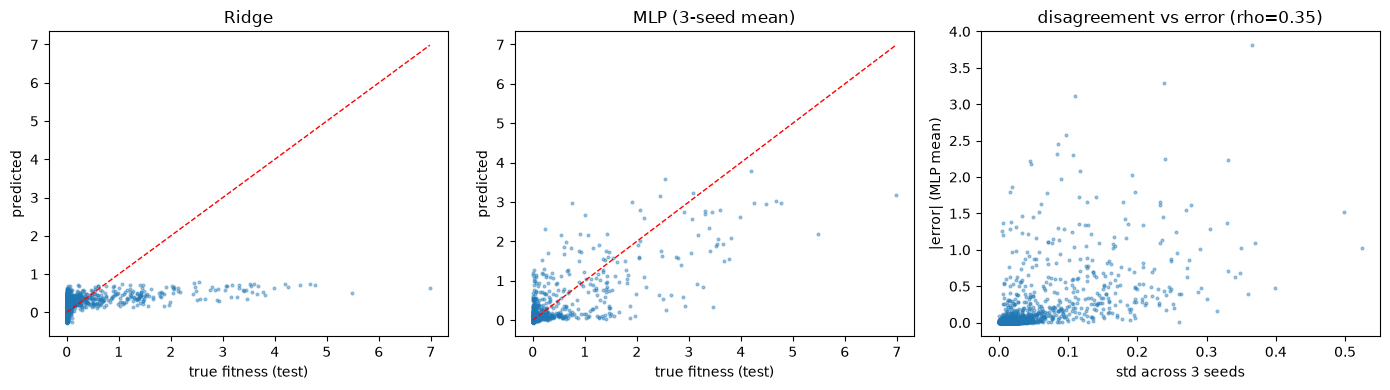

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
for a, p, t in [(ax[0], p_ridge_te, "Ridge"), (ax[1], p_mlp_te, "MLP (3-seed mean)")]:
    a.scatter(yte, p, s=4, alpha=0.4); a.set_xlabel("true fitness (test)"); a.set_ylabel("predicted"); a.set_title(t)
    lim = max(yte.max(), p.max()); a.plot([0, lim], [0, lim], "r--", lw=1)
ax[2].scatter(std_te, abs_err, s=4, alpha=0.4); ax[2].set_xlabel("std across 3 seeds"); ax[2].set_ylabel("|error| (MLP mean)")
ax[2].set_title(f"disagreement vs error (rho={rho:.2f})")
plt.tight_layout(); plt.savefig("outputs/results.png", dpi=120)